In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import (Conv1D, BatchNormalization, GRU, Dense, Dropout, 
                                     Flatten, Bidirectional, Input, Masking)
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix
import os
import pickle

class ECGClassifier:
    def __init__(self, normal_csv, abnormal_csv, test_size=0.15, val_size=0.15, random_state=42):
        self.normal_csv = normal_csv
        self.abnormal_csv = abnormal_csv
        self.test_size = test_size
        self.val_size = val_size
        self.random_state = random_state
        self.model = None
        self.scaler = None
        self.load_and_preprocess_data()

    def load_and_preprocess_data(self):
        df_normal = pd.read_csv(self.normal_csv, header=None)
        df_abnormal = pd.read_csv(self.abnormal_csv, header=None)
        df = pd.concat([df_normal, df_abnormal], axis=0)
        
        # Assume last column is the label
        X = df.iloc[:, :-1].values  
        y = df.iloc[:, -1].values   

        X_train_val, X_test, y_train_val, y_test = train_test_split(
            X, y, test_size=self.test_size, random_state=self.random_state, stratify=y
        )

        val_ratio = self.val_size / (1 - self.test_size)
        X_train, X_val, y_train, y_val = train_test_split(
            X_train_val, y_train_val, test_size=val_ratio, random_state=self.random_state, stratify=y_train_val
        )

        self.scaler = MinMaxScaler()
        X_train = self.scaler.fit_transform(X_train)
        X_val = self.scaler.transform(X_val)
        X_test = self.scaler.transform(X_test)

        # Reshape for 1D CNN / RNN (samples, timesteps, features)
        self.X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
        self.X_val = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
        self.X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)
        self.y_train, self.y_val, self.y_test = y_train, y_val, y_test

    def build_model(self):
        """Architecture: Masking + Conv1D + Bi-GRU"""
        inputs = Input(shape=(self.X_train.shape[1], 1))

        # Masking layer to handle potential zero-padding
        x = Masking(mask_value=0.)(inputs)

        x = Conv1D(filters=32, kernel_size=3, activation='relu', padding='same')(x)
        x = BatchNormalization()(x)

        x = Bidirectional(GRU(128, return_sequences=True, dropout=0.2))(x)
        x = Bidirectional(GRU(64, return_sequences=True, dropout=0.2))(x)

        x = Flatten()(x)
        
        x = Dense(128, activation='relu')(x)
        x = Dropout(0.3)(x)
        x = Dense(64, activation='relu')(x)
        outputs = Dense(1, activation='sigmoid')(x)  

        self.model = Model(inputs=inputs, outputs=outputs)
        self.model.compile(optimizer=Adam(learning_rate=0.001),
                           loss='binary_crossentropy',
                           metrics=['accuracy'])
        print(self.model.summary())

    def train_model(self, epochs=25, batch_size=128):
        self.history = self.model.fit(
            self.X_train, self.y_train,
            validation_data=(self.X_val, self.y_val),
            epochs=epochs,
            batch_size=batch_size,
            verbose=1
        )

    def plot_history(self):
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        
        # Accuracy Plot
        axes[0].plot(self.history.history['accuracy'], label='Train Accuracy')
        axes[0].plot(self.history.history['val_accuracy'], label='Val Accuracy')
        axes[0].set_title('Model Accuracy')
        axes[0].set_xlabel('Epoch')
        axes[0].set_ylabel('Accuracy')
        axes[0].legend()
        axes[0].grid(True)

        # Loss Plot
        axes[1].plot(self.history.history['loss'], label='Train Loss')
        axes[1].plot(self.history.history['val_loss'], label='Val Loss')
        axes[1].set_title('Model Loss')
        axes[1].set_xlabel('Epoch')
        axes[1].set_ylabel('Loss')
        axes[1].legend()
        axes[1].grid(True)
        
        plt.tight_layout()
        plt.show()

    def evaluate_model(self):
        test_loss, test_acc = self.model.evaluate(self.X_test, self.y_test)
        print(f"\nTest Accuracy: {test_acc*100:.2f}%")
        
        y_pred = (self.model.predict(self.X_test) > 0.5).astype(int).flatten()
        print("\nClassification Report:")
        print(classification_report(self.y_test, y_pred, digits=4))
        
    def save_model(self, model_path='ecg_model.keras', scaler_path='ecg_scaler.pkl'):
        if self.model is None:
            print("Error: Model has not been built yet!")
            return
        
        # Save Model
        self.model.save(model_path)
        print(f"✓ Model successfully saved to {model_path}")
        
        # Save Scaler
        if self.scaler is not None:
            with open(scaler_path, 'wb') as f:
                pickle.dump(self.scaler, f)
            print(f"✓ Scaler successfully saved to {scaler_path}")
        
        # File Information
        if os.path.exists(model_path):
            size_mb = os.path.getsize(model_path) / (1024 * 1024)
            print(f"  Model Size: {size_mb:.2f} MB")
    
    @staticmethod
    def load_trained_model(model_path='ecg_model.keras', scaler_path='ecg_scaler.pkl'):
        # Load Model
        model = load_model(model_path)
        print(f"✓ Model loaded from {model_path}")
        
        # Load Scaler
        scaler = None
        if os.path.exists(scaler_path):
            with open(scaler_path, 'rb') as f:
                scaler = pickle.load(f)
            print(f"✓ Scaler loaded from {scaler_path}")
        
        return model, scaler
    
    def predict_new_sample(self, new_sample):
        # Preprocessing: Scaling and Reshaping
        sample_scaled = self.scaler.transform(new_sample.reshape(1, -1))
        sample_reshaped = sample_scaled.reshape(1, sample_scaled.shape[1], 1)
        
        # Prediction
        prediction = self.model.predict(sample_reshaped, verbose=0)
        
        if prediction[0][0] > 0.5:
            return f'Abnormal (Confidence: {prediction[0][0]*100:.2f}%)'
        else:
            return f'Normal (Confidence: {(1-prediction[0][0])*100:.2f}%)'

...\site-packages\keras\src\layers\layer.py:970: UserWarning: Layer 'conv1d' (of type Conv1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 187, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ masking (Masking)               │ (None, 187, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 187, 32)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 187, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 187, 256)       │       124,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 187, 128)       │       123,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 23936)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,063,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,320,577 (12.67 MB)

 Trainable params: 3,320,513 (12.67 MB)

 Non-trainable params: 64 (256.00 B)

None
Epoch 1/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 52s 575ms/step - accuracy: 0.7913 - loss: 0.4236 - val_accuracy: 0.7219 - val_loss: 0.5188
Epoch 2/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 60s 754ms/step - accuracy: 0.8733 - loss: 0.2827 - val_accuracy: 0.7224 - val_loss: 0.5340
Epoch 3/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 67s 841ms/step - accuracy: 0.9170 - loss: 0.2023 - val_accuracy: 0.7673 - val_loss: 0.4335
Epoch 4/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 63s 786ms/step - accuracy: 0.9446 - loss: 0.1478 - val_accuracy: 0.7458 - val_loss: 0.4114
Epoch 5/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 72s 895ms/step - accuracy: 0.9553 - loss: 0.1167 - val_accuracy: 0.8136 - val_loss: 0.3378
Epoch 6/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 73s 912ms/step - accuracy: 0.9689 - loss: 0.0826 - val_accuracy: 0.8575 - val_loss: 0.3156
Epoch 7/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 74s 923ms/step - accuracy: 0.9779 - loss: 0.0631 - val_accuracy: 0.8731 - val_loss: 0.3343
Epoch 8/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 75s 942ms/step - accuracy: 0.9793 - loss: 0.0619 - val

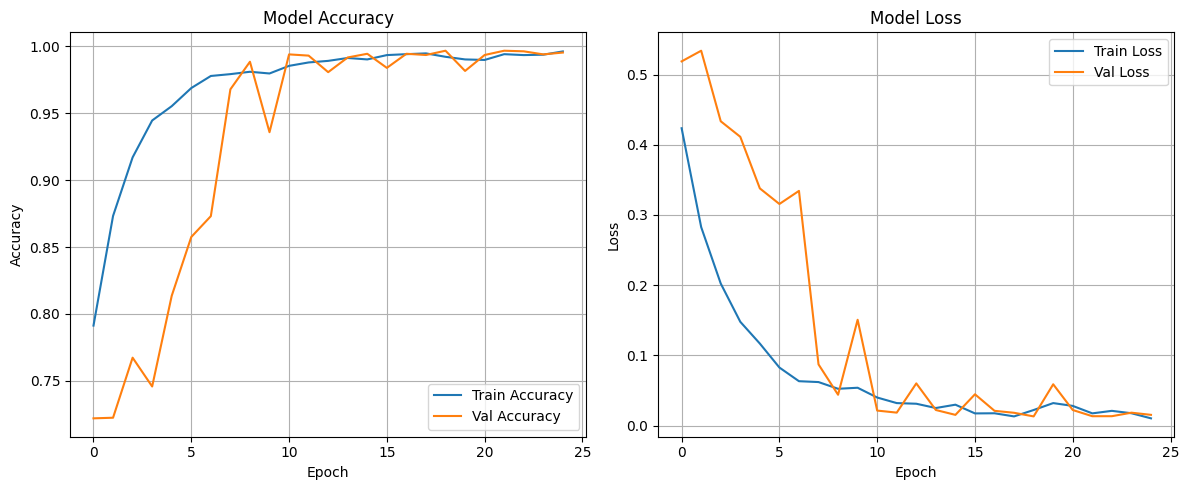

69/69 ━━━━━━━━━━━━━━━━━━━━ 4s 55ms/step - accuracy: 0.9963 - loss: 0.0242

Test Accuracy: 99.63%
69/69 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step

Classification Report:
              precision    recall  f1-score   support

         0.0     0.9983    0.9885    0.9934       607
         1.0     0.9956    0.9994    0.9975      1576

    accuracy                         0.9963      2183
   macro avg     0.9970    0.9939    0.9954      2183
weighted avg     0.9963    0.9963    0.9963      2183


 save model...
✓ Model successfully saved to ecg_model_final.keras
✓ Scaler successfully saved to ecg_scaler.pkl
  Model Size: 38.08 MB


In [2]:
if __name__ == "__main__":
    classifier = ECGClassifier(
        normal_csv="ptbdb-dataset/ptbdb_normal.csv",
        abnormal_csv="ptbdb-dataset/ptbdb_abnormal.csv"
    )

    classifier.build_model()
    classifier.train_model(epochs=25, batch_size=128)
    classifier.plot_history()
    classifier.evaluate_model()
    

    print("\n" + "="*50)
    print(" save model...")
    print("="*50)
    classifier.save_model(
        model_path='ecg_model_final.keras',
        scaler_path='ecg_scaler.pkl'
    )

In [3]:

loaded_model, loaded_scaler = ECGClassifier.load_trained_model(
    model_path='ecg_model_final.keras',
    scaler_path='ecg_scaler.pkl'
)


✓ Model loaded from ecg_model_final.keras
✓ Scaler loaded from ecg_scaler.pkl


...\site-packages\keras\src\layers\layer.py:970: UserWarning: Layer 'conv1d' (of type Conv1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


In [ ]:

test_sample = classifier.X_test[0] 


prediction = loaded_model.predict(test_sample.reshape(1, -1, 1), verbose=0)
result = "Abnormal" if prediction[0][0] > 0.5 else "Normal"
print(f"predict: {result} (p: {prediction[0][0]*100:.2f}%)")
print(f"reality: {'Abnormal' if classifier.y_test[0] == 1 else 'Normal'}")

predict: Abnormal (p: 100.00%)
reality: Abnormal


In [6]:
for i in range(10):
    test_sample = classifier.X_test[i]
    prediction = loaded_model.predict(test_sample.reshape(1, -1, 1), verbose=0)
    result = "Abnormal" if prediction[0][0] > 0.5 else "Normal"
    actual = "Abnormal" if classifier.y_test[i] == 1 else "Normal"
    
    match = "✓" if result == actual else "✗"
    print(f"{match} Predict: {result:8s} ({prediction[0][0]*100:5.1f}%) | Actual: {actual}")

✓ Predict: Abnormal (100.0%) | Actual: Abnormal
✓ Predict: Abnormal (100.0%) | Actual: Abnormal
✓ Predict: Abnormal (100.0%) | Actual: Abnormal
✓ Predict: Abnormal (100.0%) | Actual: Abnormal
✓ Predict: Abnormal (100.0%) | Actual: Abnormal
✓ Predict: Normal   (  0.0%) | Actual: Normal
✓ Predict: Abnormal (100.0%) | Actual: Abnormal
✓ Predict: Abnormal (100.0%) | Actual: Abnormal
✓ Predict: Abnormal (100.0%) | Actual: Abnormal
✓ Predict: Abnormal (100.0%) | Actual: Abnormal
